# Member 5 — Explainable AI, dashboard & integration
Module: `src/explain.py`, app: `app/streamlit_app.py`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
def show(name): display(Image(filename=str(C.FIG_DIR / f'{name}.png')))
def tbl(name): return pd.read_csv(C.TABLE_DIR / f'{name}.csv')

In [2]:
summary = json.loads((C.ROOT / 'reports' / 'summary.json').read_text()); summary['explainability']

{'spearman_shap_vs_ig': 0.811,
 'top5_shap': ['request_amount_roundness',
  'amount',
  'transaction_time_of_day',
  'keyboard_input_speed',
  'transaction_amount_vs_sender_history'],
 'top5_ig': ['request_amount_roundness',
  'amount',
  'transaction_time_of_day',
  'input_timing_consistency',
  'transaction_amount_vs_sender_history'],
 'top5_lstm': ['amount',
  'request_amount_roundness',
  'input_timing_consistency',
  'transaction_time_of_day',
  'input_pause_patterns'],
 'agreement_vs_leakage': {'T2a_behavioural_with_geo_pair': {'spearman': 0.473,
   'top3_shap': ['amount',
    'request_amount_roundness',
    'transaction_time_of_day'],
   'top3_ig': ['request_amount_roundness', 'amount', 'geographic_disparity']},
  'T2_behavioural': {'spearman': 0.832,
   'top3_shap': ['request_amount_roundness',
    'amount',
    'transaction_time_of_day'],
   'top3_ig': ['request_amount_roundness',
    'amount',
    'transaction_time_of_day']}}}

## 1. XGBoost — SHAP (TreeExplainer)

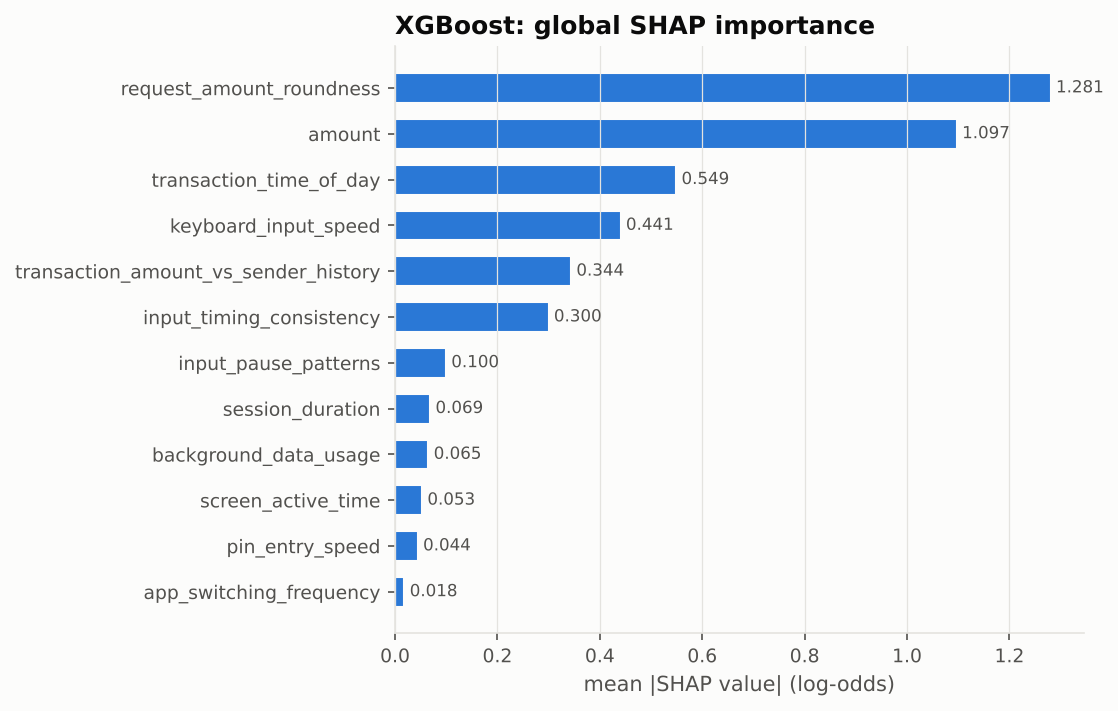

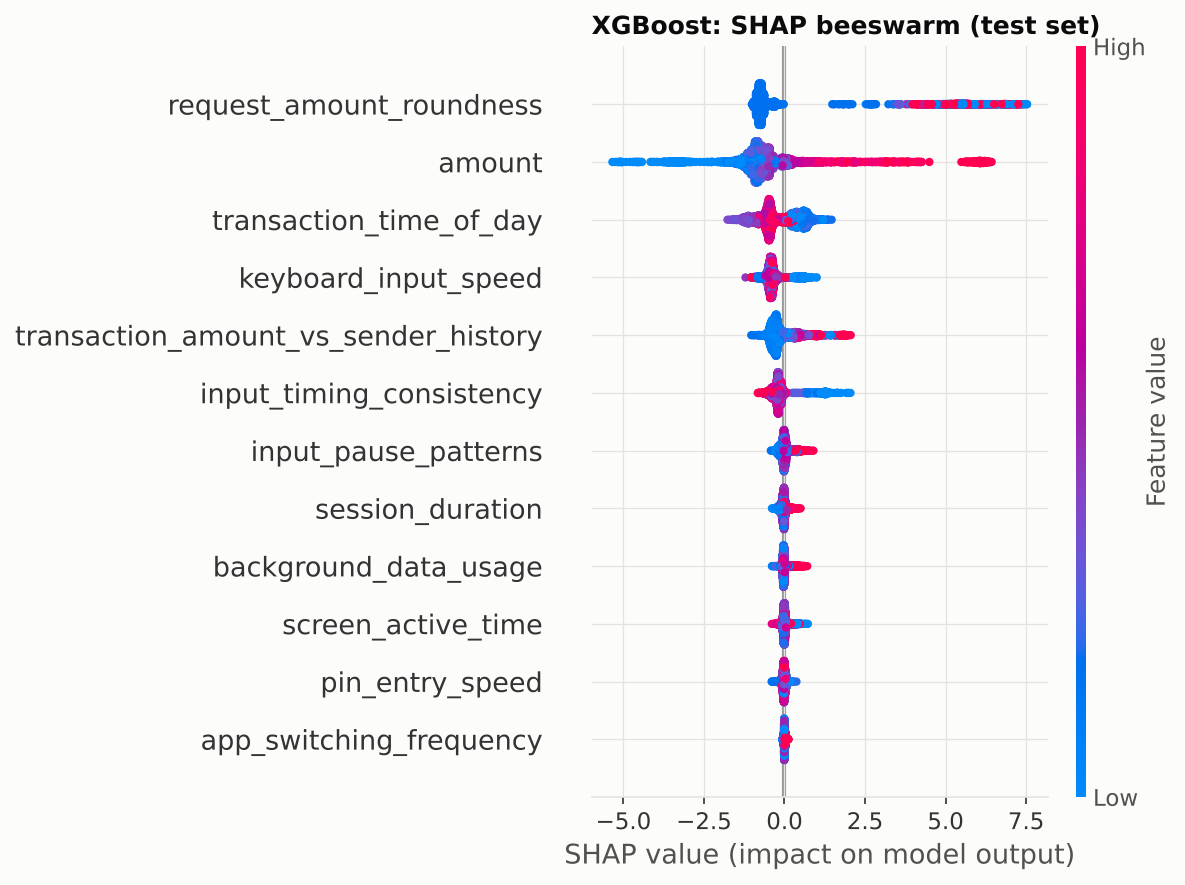

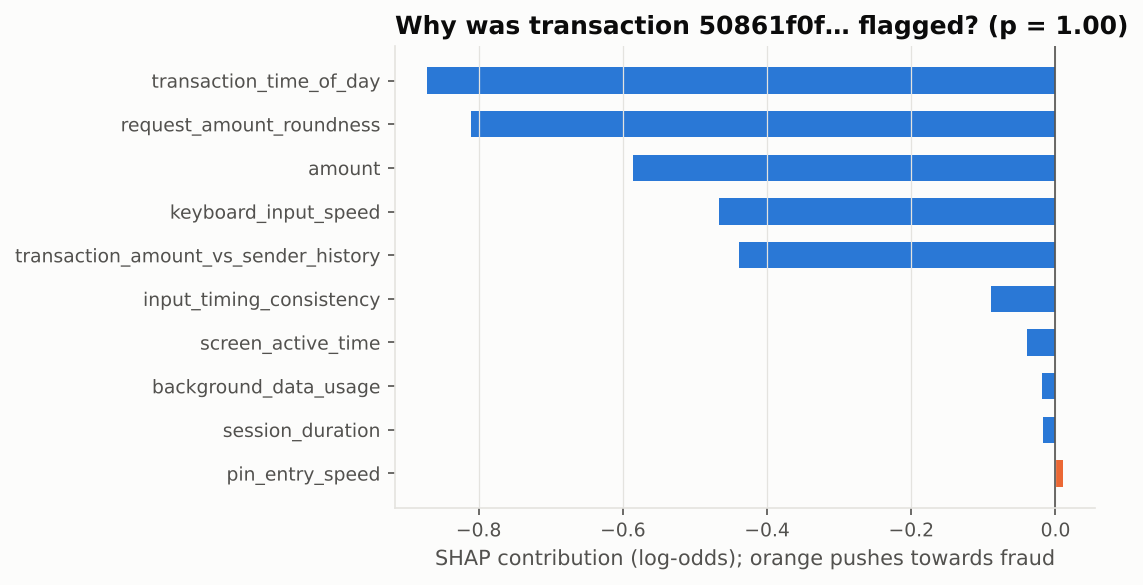

In [3]:
show('20_shap_global_xgboost'); show('21_shap_beeswarm_xgboost'); show('22_shap_local_example')

## 2. MLP — Integrated Gradients
IG integrates the gradient along a straight path from a baseline (the training mean) to the input; attributions sum to the change in logit.

completeness check (sum of attributions vs logit difference), mean abs error: 0.0453


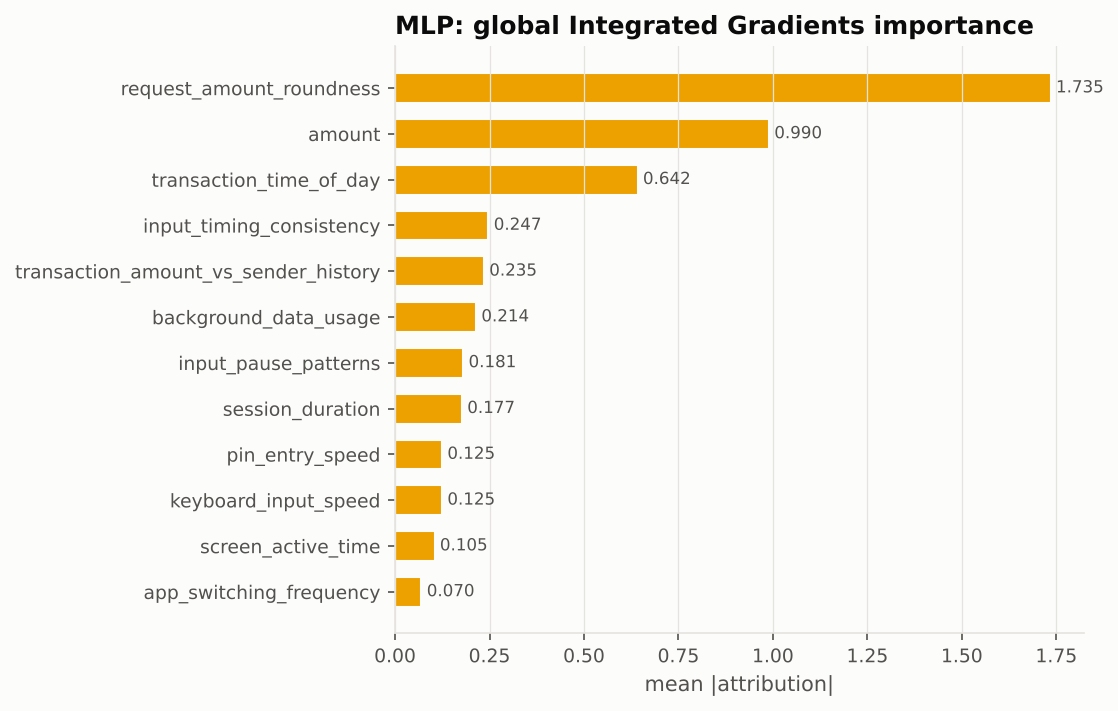

In [4]:
from src.features import prepare_dataset
from src.splits import get_split
from src.models_deep import TorchClassifier
from src.explain import integrated_gradients
meta = json.loads((C.MODELS_DIR / 'model_meta.json').read_text())
df = prepare_dataset(); split = get_split(df); cols = meta['feature_columns']
mlp = TorchClassifier.load(C.MODELS_DIR / 'mlp.pt')
X = df.iloc[split['test']][cols].values.astype('float32')[:300]
ig = integrated_gradients(mlp, X)
import torch
with torch.no_grad():
    lx = mlp.model(torch.from_numpy(mlp._scale(X))); l0 = mlp.model(torch.zeros(1, X.shape[1]))
print('completeness check (sum of attributions vs logit difference), mean abs error:',
      float(np.abs(ig.sum(1) - (lx - l0).numpy()).mean()).__round__(4))
show('23_ig_global_mlp')

## 3. LSTM — permutation importance

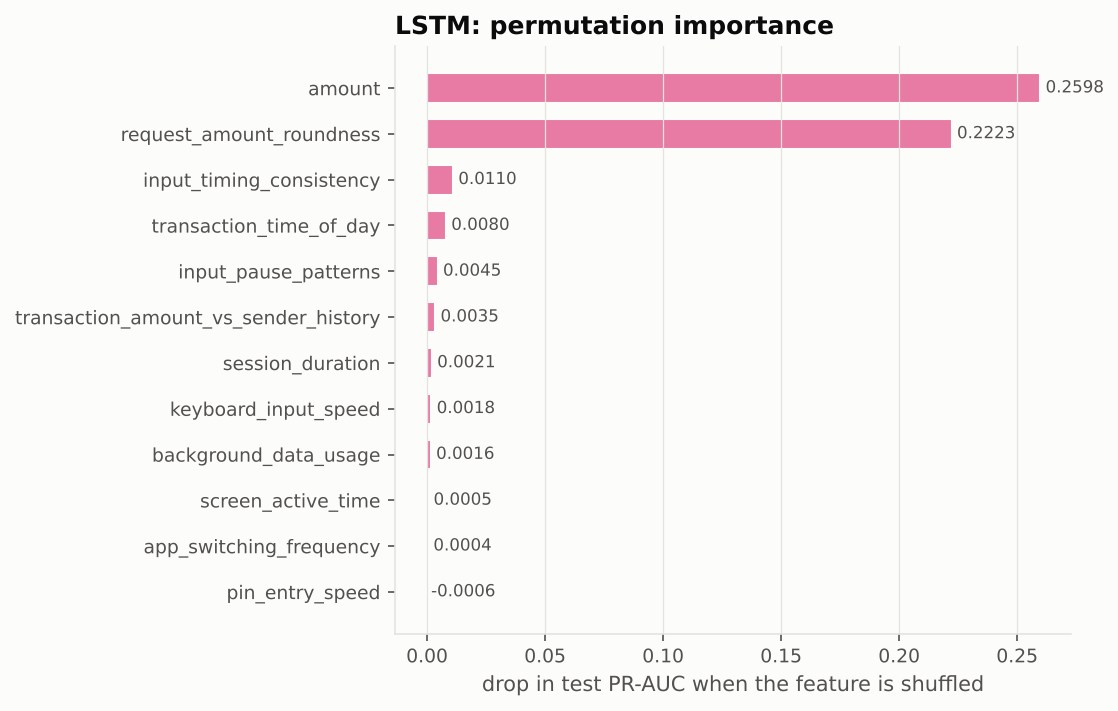

,feature,pr_auc_drop
0,amount,0.25980
1,request_amount_roundness,0.22227
2,input_timing_consistency,0.01100
3,transaction_time_of_day,0.00801
4,input_pause_patterns,0.00451
5,transaction_amount_vs_sender_history,0.00346
6,session_duration,0.00205
7,keyboard_input_speed,0.00185
8,background_data_usage,0.00160
9,screen_active_time,0.00051


In [5]:
show('24_lstm_permutation_importance'); tbl('exp7_lstm_permutation_importance')

## 4. Do the explanations agree?

In [6]:
tbl('exp7_explainability_comparison')

,feature,shap_xgboost,ig_mlp,shap_rank,ig_rank
0,request_amount_roundness,1.28069,1.73524,1,1
1,amount,1.09731,0.98972,2,2
2,transaction_time_of_day,0.54921,0.64212,3,3
3,keyboard_input_speed,0.44066,0.12453,4,10
4,transaction_amount_vs_sender_history,0.34387,0.23534,5,5
5,input_timing_consistency,0.29998,0.24726,6,4
6,input_pause_patterns,0.09956,0.18057,7,7
7,session_duration,0.06867,0.17716,8,8
8,background_data_usage,0.06522,0.21446,9,6
9,screen_active_time,0.05290,0.10471,10,11


## 5. Explanations as a leakage detector (Exp 7b)
If two very different models explain the same data differently, ask why. With the leaky geographic pair the MLP ranked `geographic_disparity` in its top 3 while XGBoost did not; once the pair was removed, agreement rose sharply.

In [7]:
tbl('exp7b_agreement_vs_leakage')

,feature_set,spearman,top3_shap,top3_ig
0,T2a_behavioural_with_geo_pair,0.473,"['amount', 'request_amount_roundness', 'transa...","['request_amount_roundness', 'amount', 'geogra..."
1,T2_behavioural,0.832,"['request_amount_roundness', 'amount', 'transa...","['request_amount_roundness', 'amount', 'transa..."


## 6. Dashboard
From the project root run:
```bash
streamlit run app/streamlit_app.py
```
Pages: Overview · Leakage audit · Model comparison · Deep learning & sequences · Transaction monitor (risk scores + per-transaction SHAP) · Threshold & cost (editable cost assumptions) · Score a transaction (what-if) · Explainability.